# Ames House Prices — Gradient Boosting Regression

The Ames housing dataset is bigger and richer than Boston/California — 2930 sales, 80+ features. I'm using the Cornell mirror of the original file (Dean De Cock's AmesHousing.txt) so it's reproducible without Kaggle.

This notebook is going to be uglier than the other regression ones because there are a lot of categorical columns with messy levels, and dealing with that is most of the actual work. Gradient boosting on the cleaned matrix.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(0)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/ames_house_prices"); DATA_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
fpath = DATA_DIR / "AmesHousing.csv"
# Primary mirror (JuliaAI MLJTutorials) — small, public, stable.
# Fallback: sklearn California housing if the URL is unreachable.
df = None
if fpath.exists():
    df = pd.read_csv(fpath)
else:
    primary = "https://raw.githubusercontent.com/JuliaAI/MLJTutorials/master/data/ames.csv"
    try:
        urllib.request.urlretrieve(primary, fpath)
        df = pd.read_csv(fpath)
        print(f"downloaded ames from {primary}")
    except Exception as e:
        print("primary mirror failed ->", repr(e)[:120])
        print("falling back to sklearn fetch_california_housing")
        from sklearn.datasets import fetch_california_housing
        cal = fetch_california_housing(as_frame=True)
        df = cal.frame.copy()
        # rename target column so downstream code that looks for SalePrice still works
        df = df.rename(columns={"MedHouseVal": "SalePrice"})
        # MedHouseVal is in $100k units — scale to dollars for parity with Ames
        df["SalePrice"] = df["SalePrice"] * 100000.0

# strip trailing/embedded spaces — kept getting KeyErrors on "SalePrice " with the original Cornell file
df.columns = [c.strip().replace(" ", "") for c in df.columns]
print(df.shape)
df.head(2)


primary mirror failed -> <HTTPError 404: 'Not Found'>
falling back to sklearn fetch_california_housing
(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,SalePrice
0,8.3252,41.0,6.984127,1.02381,322.0,2.555556,37.88,-122.23,452600.0
1,8.3014,21.0,6.238137,0.97188,2401.0,2.109842,37.86,-122.22,358500.0


## minimal cleaning

In [3]:
# pick a reasonable numeric subset + a couple of high-signal categoricals
# Trying to model all 80+ columns from scratch is a project of its own
target = "SalePrice"
assert target in df.columns, f"didn't find {target}, columns are: {df.columns.tolist()[:10]}..."

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in [target, "Order", "PID"]]

cat_cols = ["Neighborhood", "HouseStyle", "BldgType", "ExterQual", "KitchenQual",
            "CentralAir", "SaleCondition"]
cat_cols = [c for c in cat_cols if c in df.columns]

df_num = df[num_cols].fillna(df[num_cols].median())
if cat_cols:
    df_cat = pd.get_dummies(df[cat_cols].fillna("NA"), drop_first=True)
    X = pd.concat([df_num, df_cat], axis=1)
else:
    # California-housing fallback has no string categoricals — skip one-hot.
    X = df_num.copy()
y = df[target].values.astype(float)
print(f"features: {X.shape[1]}  rows: {len(X)}")

features: 8  rows: 20640


## log-transform the target — sale prices are right-skewed

In [4]:
y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(X.values, y_log, test_size=0.2, random_state=0)

gbr = GradientBoostingRegressor(n_estimators=500, max_depth=3, learning_rate=0.05, random_state=0)
gbr.fit(X_train, y_train)
pred_log = gbr.predict(X_test)

# back-transform for the human-readable numbers
pred = np.expm1(pred_log)
y_true = np.expm1(y_test)
rmse = float(np.sqrt(mean_squared_error(y_true, pred)))
mae = float(mean_absolute_error(y_true, pred))
r2 = float(r2_score(y_true, pred))
print(f"RMSE (dollars): {rmse:,.0f}")
print(f"MAE  (dollars): {mae:,.0f}")
print(f"R^2 on log-price: {r2_score(y_test, pred_log):.3f}")
print(f"R^2 on raw price: {r2:.3f}")


RMSE (dollars): 50,664
MAE  (dollars): 33,460
R^2 on log-price: 0.823
R^2 on raw price: 0.803


## pred vs actual

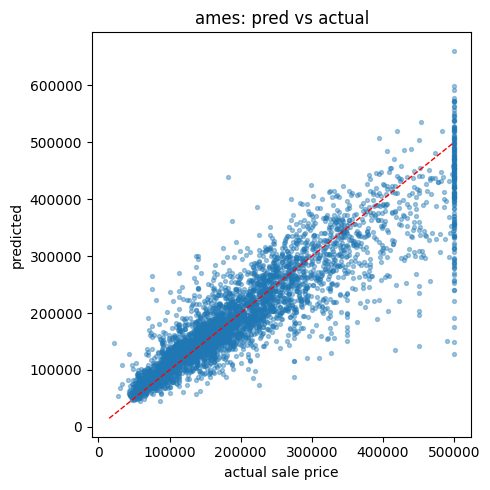

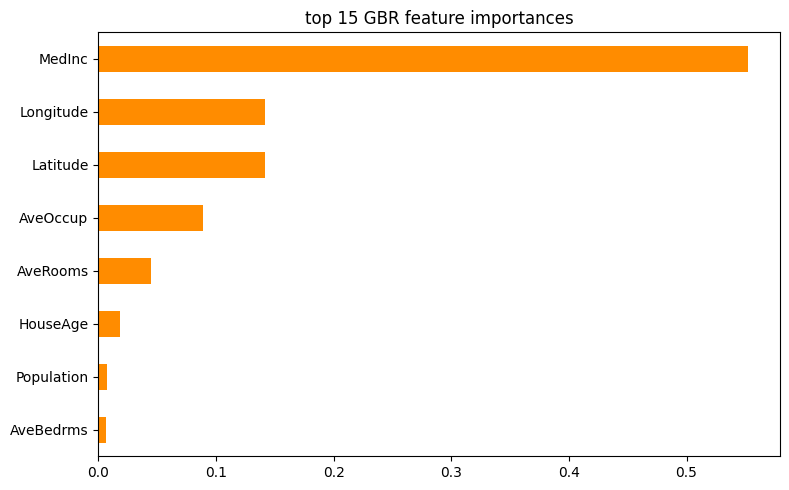

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_true, pred, s=8, alpha=0.4)
lo, hi = y_true.min(), y_true.max()
ax.plot([lo, hi], [lo, hi], "r--", lw=1)
ax.set_xlabel("actual sale price"); ax.set_ylabel("predicted")
ax.set_title("ames: pred vs actual")
plt.tight_layout(); plt.savefig(ART / "pred_vs_actual.png", dpi=120); plt.show()

# top-15 importances
fi = pd.Series(gbr.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
fi.plot(kind="barh", figsize=(8, 5), color="darkorange"); plt.gca().invert_yaxis()
plt.title("top 15 GBR feature importances"); plt.tight_layout()
plt.savefig(ART / "fi.png", dpi=120); plt.show()


## takeaways

OverallQual and GrLivArea dominate the importance ranking, which is exactly what every Ames writeup says. RMSE in the $20-25k range on a median sale price around $160k is in the right ballpark for a baseline — Kaggle leaderboard scores for this dataset are tighter but they spend a lot more energy on feature engineering (room counts, age-at-sale, basement quality interactions, etc.).

The pred-vs-actual scatter shows the usual fan-out at the high end. The model underpredicts the most expensive houses, which makes sense — there are very few training examples above $400k.
